In [2141]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

dl = pd.read_csv(r"C:\Users\Haidar\PROJEK\TUGAS\ANALISIS EKSPLORASI\DATA 1\Balaji Fast Food Sales.csv")

In [2142]:
dl

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
995,996,3/19/2023,Frankie,Fastfood,50,10,500,NaN,Mrs.,Evening
996,997,9/20/2022,Sandwich,Fastfood,60,7,420,NaN,Mr.,Evening
997,998,1/26/2023,Sandwich,Fastfood,60,13,780,NaN,Mr.,Evening
998,999,8/27/2022,Panipuri,Fastfood,20,5,100,NaN,Mrs.,Afternoon


In [2143]:
df=dl.dropna()

In [2144]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
5,6,11/14/2022,Vadapav,Fastfood,20,10,200,Cash,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
991,992,10/21/2022,Sandwich,Fastfood,60,5,300,Cash,Mr.,Morning
992,993,7/17/2022,Frankie,Fastfood,50,3,150,Online,Mrs.,Night
993,994,11-01-2022,Panipuri,Fastfood,20,2,40,Online,Mrs.,Evening
994,995,6/18/2022,Sugarcane juice,Beverages,25,1,25,Online,Mr.,Night


In [2145]:
df['total_income']=df['quantity']*df['transaction_amount']

In [2146]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale,total_income
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon,4500
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon,20
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night,900
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening,1600
5,6,11/14/2022,Vadapav,Fastfood,20,10,200,Cash,Mr.,Evening,2000
...,...,...,...,...,...,...,...,...,...,...,...
991,992,10/21/2022,Sandwich,Fastfood,60,5,300,Cash,Mr.,Morning,1500
992,993,7/17/2022,Frankie,Fastfood,50,3,150,Online,Mrs.,Night,450
993,994,11-01-2022,Panipuri,Fastfood,20,2,40,Online,Mrs.,Evening,80
994,995,6/18/2022,Sugarcane juice,Beverages,25,1,25,Online,Mr.,Night,25


In [2147]:
df['total_income'].mean()

np.float64(2854.6640537514)

In [2148]:
df_category = df.groupby(['order_id','item_name'])['item_type'].sum().reset_index()

In [2149]:
df_category

,order_id,item_name,item_type
0,2,Vadapav,Fastfood
1,3,Vadapav,Fastfood
2,4,Sugarcane juice,Beverages
3,5,Sugarcane juice,Beverages
4,6,Vadapav,Fastfood
...,...,...,...
888,992,Sandwich,Fastfood
889,993,Frankie,Fastfood
890,994,Panipuri,Fastfood
891,995,Sugarcane juice,Beverages


In [2150]:
df['item_type'].value_counts()

item_type
Fastfood     619
Beverages    274
Name: count, dtype: int64

In [2151]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [2152]:
df['time_of_sale'].value_counts()

time_of_sale
Evening      185
Night        182
Afternoon    181
Midnight     177
Morning      168
Name: count, dtype: int64

In [2153]:
df['date'] = pd.to_datetime(df['date'], format='mixed').dt.strftime('%Y-%m-%d')
df['date'] = pd.to_datetime(df['date'], format='mixed')
df['month']=df['date'].dt.strftime('%B %Y')
df['day'] = df['date'].dt.day_name()

In [2154]:
df=df.drop(columns='received_by') 
df.reset_index()
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,total_income,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,4500,August 2022,Tuesday
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Afternoon,20,November 2022,Sunday
3,4,2023-02-03,Sugarcane juice,Beverages,25,6,150,Online,Night,900,February 2023,Friday
4,5,2022-10-02,Sugarcane juice,Beverages,25,8,200,Online,Evening,1600,October 2022,Sunday
5,6,2022-11-14,Vadapav,Fastfood,20,10,200,Cash,Evening,2000,November 2022,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...
991,992,2022-10-21,Sandwich,Fastfood,60,5,300,Cash,Morning,1500,October 2022,Friday
992,993,2022-07-17,Frankie,Fastfood,50,3,150,Online,Night,450,July 2022,Sunday
993,994,2022-11-01,Panipuri,Fastfood,20,2,40,Online,Evening,80,November 2022,Tuesday
994,995,2022-06-18,Sugarcane juice,Beverages,25,1,25,Online,Night,25,June 2022,Saturday


In [2155]:
df_sale = df.groupby('order_id').agg({'item_name':'first','item_price':'first','quantity':'sum'}).reset_index()

In [2156]:
df_sale

,order_id,item_name,item_price,quantity
0,2,Vadapav,20,15
1,3,Vadapav,20,1
2,4,Sugarcane juice,25,6
3,5,Sugarcane juice,25,8
4,6,Vadapav,20,10
...,...,...,...,...
888,992,Sandwich,60,5
889,993,Frankie,50,3
890,994,Panipuri,20,2
891,995,Sugarcane juice,25,1


In [2157]:
df_order = df.groupby(['order_id','item_name', 'date', 'day', 'time_of_sale','month']).agg({'quantity': 'sum'})

In [2158]:
df_order

,,,,,,quantity
order_id,item_name,date,day,time_of_sale,month,
2,Vadapav,2022-08-23,Tuesday,Afternoon,August 2022,15
3,Vadapav,2022-11-20,Sunday,Afternoon,November 2022,1
4,Sugarcane juice,2023-02-03,Friday,Night,February 2023,6
5,Sugarcane juice,2022-10-02,Sunday,Evening,October 2022,8
6,Vadapav,2022-11-14,Monday,Evening,November 2022,10
...,...,...,...,...,...,...
992,Sandwich,2022-10-21,Friday,Morning,October 2022,5
993,Frankie,2022-07-17,Sunday,Night,July 2022,3
994,Panipuri,2022-11-01,Tuesday,Evening,November 2022,2


In [2174]:
# Solusi 1: Langsung reset_index() saat groupby (Paling Rapi)
df_order = df.groupby(['order_id', 'item_name', 'date', 'day', 'time_of_sale', 'month'], as_index=False).agg({'quantity': 'sum'})

# Ekspor ke CSV
df_order.to_csv('CLEAN/orders.csv', sep=';', index=False)

C:\Users\Haidar\AppData\Local\Temp\ipykernel_18948\2859541873.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_day_sum, x='day', y='quantity', palette='Blues_r')


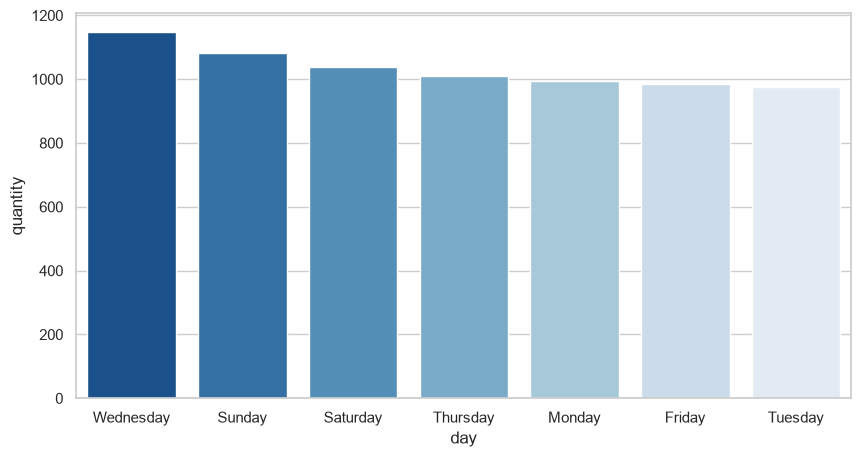

In [2160]:
df_day_sum = df_order.groupby('day', as_index=False)['quantity'].sum()

# 2. Urutkan dari yang terbanyak
df_day_sum = df_day_sum.sort_values(by='quantity', ascending=False)

# 3. Plot menggunakan barplot (bukan countplot)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_day_sum, x='day', y='quantity', palette='Blues_r')

In [2161]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,total_income,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,4500,August 2022,Tuesday
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Afternoon,20,November 2022,Sunday
3,4,2023-02-03,Sugarcane juice,Beverages,25,6,150,Online,Night,900,February 2023,Friday
4,5,2022-10-02,Sugarcane juice,Beverages,25,8,200,Online,Evening,1600,October 2022,Sunday
5,6,2022-11-14,Vadapav,Fastfood,20,10,200,Cash,Evening,2000,November 2022,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...
991,992,2022-10-21,Sandwich,Fastfood,60,5,300,Cash,Morning,1500,October 2022,Friday
992,993,2022-07-17,Frankie,Fastfood,50,3,150,Online,Night,450,July 2022,Sunday
993,994,2022-11-01,Panipuri,Fastfood,20,2,40,Online,Evening,80,November 2022,Tuesday
994,995,2022-06-18,Sugarcane juice,Beverages,25,1,25,Online,Night,25,June 2022,Saturday


In [2162]:
# 1. Buat kolom periode bulan di DataFrame
df['month'] = pd.to_datetime(df['month'], format='mixed').dt.to_period('M')

# 2. Groupby berdasarkan periode bulan lalu jumlahkan quantity
df_tahun = (
    df.groupby('month').agg({'quantity':'sum'})
    .sort_index()
)

# 3. Ubah format index ke nama bulan dan tahun (misal: April 2022)
df_tahun.index = df_tahun.index.to_timestamp().strftime('%B %Y')

# 4. KUNCI: Gunakan reset_index(inplace=True) agar kolom 'month' muncul sebagai kolom biasa
df_tahun = df_tahun.reset_index()

df_tahun

,month,quantity
0,April 2022,438
1,May 2022,736
2,June 2022,435
3,July 2022,544
4,August 2022,662
5,September 2022,466
6,October 2022,728
7,November 2022,611
8,December 2022,669
9,January 2023,669


In [2163]:
df_plot = df_tahun.reset_index()

In [2164]:
df_plot

,index,month,quantity
0,0,April 2022,438
1,1,May 2022,736
2,2,June 2022,435
3,3,July 2022,544
4,4,August 2022,662
5,5,September 2022,466
6,6,October 2022,728
7,7,November 2022,611
8,8,December 2022,669
9,9,January 2023,669


In [2165]:
df.groupby('month').agg({'quantity': 'sum','time_of_sale':'first'})

,quantity,time_of_sale
month,,
2022-04,438,Morning
2022-05,736,Evening
2022-06,435,Morning
2022-07,544,Night
2022-08,662,Afternoon
2022-09,466,Afternoon
2022-10,728,Evening
2022-11,611,Afternoon
2022-12,669,Night


In [2166]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [2167]:
df.nlargest(10,'quantity')

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,total_income,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,4500,2022-08,Tuesday
20,21,2022-12-21,Cold coffee,Beverages,40,15,600,Cash,Evening,9000,2022-12,Wednesday
50,51,2022-05-16,Frankie,Fastfood,50,15,750,Online,Morning,11250,2022-05,Monday
85,86,2023-03-09,Aalopuri,Fastfood,20,15,300,Cash,Morning,4500,2023-03,Thursday
89,90,2022-10-29,Vadapav,Fastfood,20,15,300,Online,Night,4500,2022-10,Saturday
91,92,2022-05-13,Aalopuri,Fastfood,20,15,300,Cash,Afternoon,4500,2022-05,Friday
135,136,2022-08-24,Aalopuri,Fastfood,20,15,300,Online,Morning,4500,2022-08,Wednesday
137,138,2022-09-01,Sandwich,Fastfood,60,15,900,Online,Night,13500,2022-09,Thursday
186,187,2022-10-11,Aalopuri,Fastfood,20,15,300,Cash,Morning,4500,2022-10,Tuesday
192,193,2023-02-05,Cold coffee,Beverages,40,15,600,Online,Midnight,9000,2023-02,Sunday


In [2168]:
l=df.groupby('item_name')['time_of_sale'].value_counts().reset_index()
l
##nanti buat visualisasi yang nampilin perbandingan waktu di satu item kalo bisa dibuat kaya filter item

,item_name,time_of_sale,count
0,Aalopuri,Midnight,30
1,Aalopuri,Morning,25
2,Aalopuri,Afternoon,24
3,Aalopuri,Night,23
4,Aalopuri,Evening,17
5,Cold coffee,Night,33
6,Cold coffee,Morning,28
7,Cold coffee,Evening,27
8,Cold coffee,Afternoon,27
9,Cold coffee,Midnight,23


In [2169]:
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

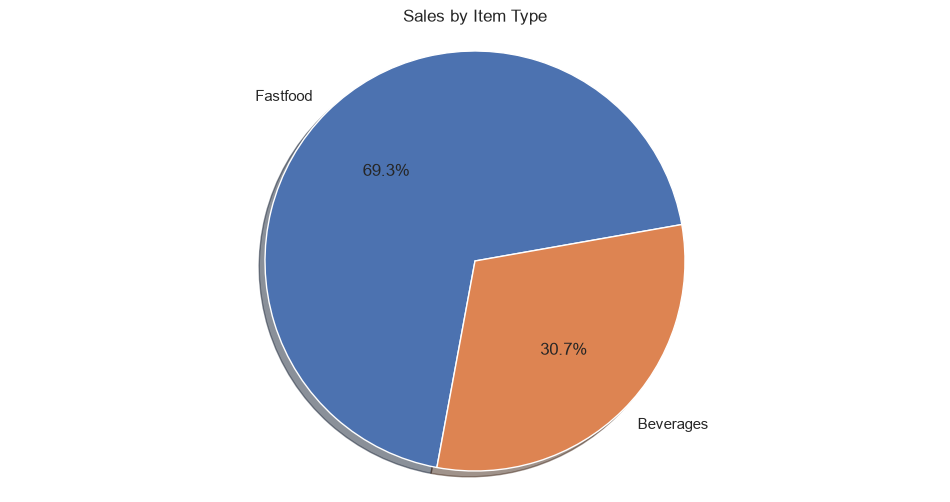

In [2170]:
plt.figure(figsize=(12,6))
df['item_type'].value_counts().plot(kind='pie',shadow=True,startangle=10, color='skyblue', autopct='%1.1f%%')
plt.title('Sales by Item Type')
plt.axis('equal')
plt.show()

In [2171]:
df_sale

,order_id,item_name,item_price,quantity
0,2,Vadapav,20,15
1,3,Vadapav,20,1
2,4,Sugarcane juice,25,6
3,5,Sugarcane juice,25,8
4,6,Vadapav,20,10
...,...,...,...,...
888,992,Sandwich,60,5
889,993,Frankie,50,3
890,994,Panipuri,20,2
891,995,Sugarcane juice,25,1


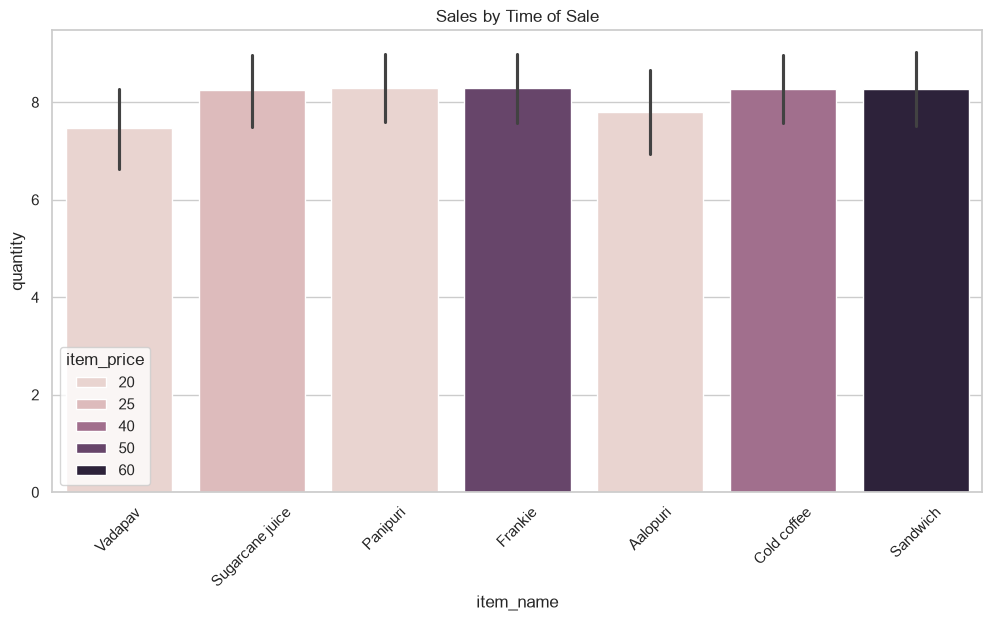

In [2172]:
plt.figure(figsize=(12,6))

sns.set_theme(style='whitegrid')
sns.barplot(data=df_sale, x = 'item_name',y='quantity',hue='item_price')
plt.xticks(rotation=45)
plt.xlabel=('Produk')
plt.ylabel=('Count')
plt.title('Sales by Time of Sale')
plt.show()

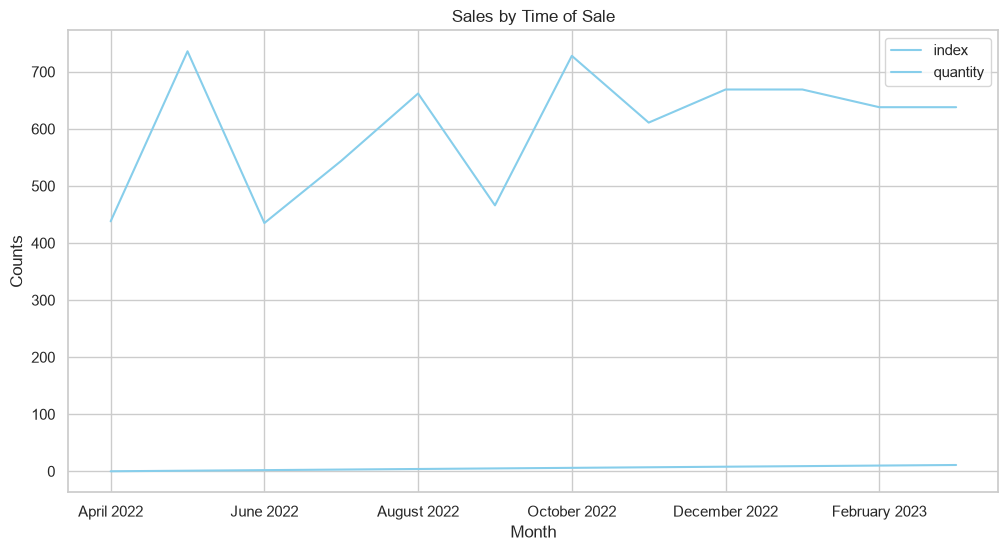

In [2173]:
ax = df_plot.plot(kind='line', x='month',figsize=(12, 6), color='skyblue',grid=True)

ax.set_xlabel('Month')
ax.set_ylabel('Counts')
ax.set_title('Sales by Time of Sale')
plt.show()

